<a href="https://colab.research.google.com/github/fuaadrahman/Exploratory-Data-Analysis-EDA-/blob/main/IPL_Team_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Dataset

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/matches.csv')
df.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


Size and Info of Dataset

In [ ]:
df.shape

(756, 18)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   id               756 non-null    int64 
 1   season           756 non-null    int64 
 2   city             749 non-null    object
 3   date             756 non-null    object
 4   team1            756 non-null    object
 5   team2            756 non-null    object
 6   toss_winner      756 non-null    object
 7   toss_decision    756 non-null    object
 8   result           756 non-null    object
 9   dl_applied       756 non-null    int64 
 10  winner           752 non-null    object
 11  win_by_runs      756 non-null    int64 
 12  win_by_wickets   756 non-null    int64 
 13  player_of_match  752 non-null    object
 14  venue            756 non-null    object
 15  umpire1          754 non-null    object
 16  umpire2          754 non-null    object
 17  umpire3          119 non-null    ob

In [ ]:
df.columns.to_list()

['id',
 'season',
 'city',
 'date',
 'team1',
 'team2',
 'toss_winner',
 'toss_decision',
 'result',
 'dl_applied',
 'winner',
 'win_by_runs',
 'win_by_wickets',
 'player_of_match',
 'venue',
 'umpire1',
 'umpire2',
 'umpire3']

Dataset After Renaming Team name and Removing unwanted columns

In [ ]:
df = df.drop(['umpire1','umpire2','umpire3'], axis=1)
team_map = {"Chennai Super Kings":"CSK", "Deccan Chargers":"DCH", "Delhi Daredevils":"DD",
            "Delhi Capitals":"DC", "Gujarat Lions":"GL", "Kings XI Punjab":"KXIP",
            "Kochi Tuskers Kerala":"KTK", "Kolkata Knight Riders":"KKR", "Mumbai Indians":"MI",
            "Pune Warriors":"PWI", "Rajasthan Royals":"RR", "Rising Pune Supergiant":"RPS",
            "Rising Pune Supergiants":"RPS", "Royal Challengers Bangalore":"RCB",
            "Sunrisers Hyderabad":"SRH"}

for i in ["team1", "team2", "toss_winner", "winner"]:
    df[i] = df[i].astype("string").str.strip().replace(team_map)
df.head()

,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue
0,1,2017,Hyderabad,2017-04-05,SRH,RCB,RCB,field,normal,0,SRH,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal"
1,2,2017,Pune,2017-04-06,MI,RPS,RPS,field,normal,0,RPS,0,7,SPD Smith,Maharashtra Cricket Association Stadium
2,3,2017,Rajkot,2017-04-07,GL,KKR,KKR,field,normal,0,KKR,0,10,CA Lynn,Saurashtra Cricket Association Stadium
3,4,2017,Indore,2017-04-08,RPS,KXIP,KXIP,field,normal,0,KXIP,0,6,GJ Maxwell,Holkar Cricket Stadium
4,5,2017,Bangalore,2017-04-08,RCB,DD,RCB,bat,normal,0,RCB,15,0,KM Jadhav,M Chinnaswamy Stadium


Duplicates and missing values

In [ ]:
df[df.duplicated()].shape

(0, 15)

In [ ]:
df.isnull().sum()

,0
id,0
season,0
city,7
date,0
team1,0
team2,0
toss_winner,0
toss_decision,0
result,0
dl_applied,0


In [ ]:
# How many matches ended in a tie or had no result?
results=df["result"].astype("string")
ties=(results=="tie").sum()
no_results=(results=="no result").sum()
print(f"Tied matches:{ties}")
print(f"Matches with no result:{no_results}")

Tied matches:9
Matches with no result:4


In [ ]:
# How many matches dl applied?
dl_applied=(df["dl_applied"]==1).sum()
print(f"No:of matches Duckworth-Lewis method applied: {dl_applied}")

No:of matches Duckworth-Lewis method applied: 19


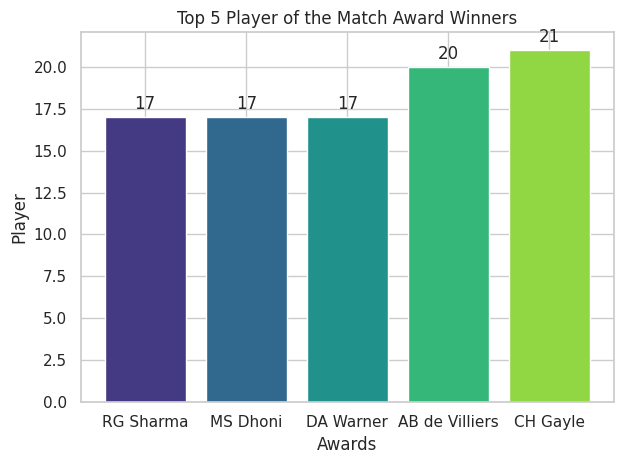

In [ ]:
top5 = df["player_of_match"].value_counts().head(5).sort_values()
bars = plt.bar(top5.index,top5.values,color=sns.color_palette("viridis", len(top5)))
plt.bar_label(bars, padding=3)
plt.title("Top 5 Player of the Match Award Winners")
plt.xlabel("Awards")
plt.ylabel("Player")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1094/1224758249.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y="winner", data=df, order=df["winner"].value_counts().index, palette="copper")


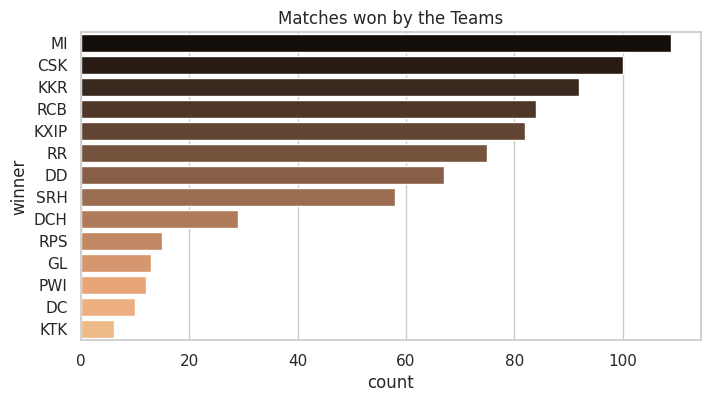

In [ ]:
plt.figure(figsize=(8,4))
sns.countplot(y="winner", data=df, order=df["winner"].value_counts().index, palette="copper")
plt.title("Matches won by the Teams")
plt.show()

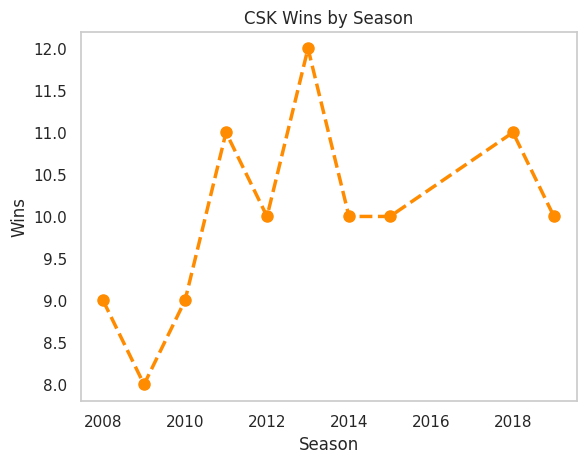

In [ ]:
df[df.winner == "CSK"].groupby("season").size().plot(
    kind="line", marker="o",color="darkorange", linewidth=2.5,
    markersize=8, linestyle="--", title="CSK Wins by Season",
    xlabel="Season", ylabel="Wins"
)
plt.grid()
plt.show()

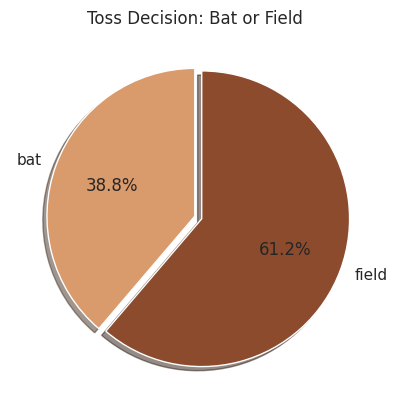

In [ ]:
df["toss_decision"].value_counts().plot(kind="pie",autopct="%1.1f%%",startangle=90,counterclock=False,
ylabel="",title="Toss Decision: Bat or Field",explode=[0.05, 0],shadow=True,colors=["#8c4b2d", "#d99a6c"])
plt.show()

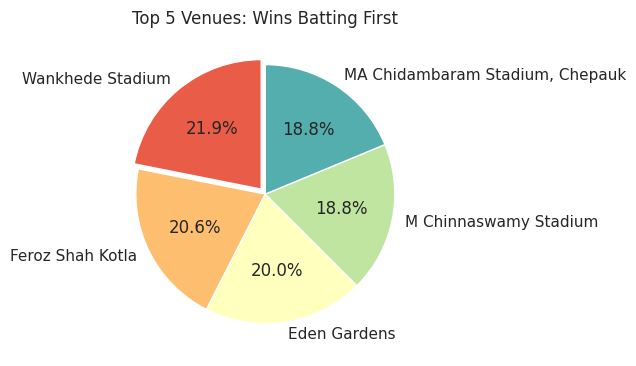

In [ ]:
first = (df[(df["win_by_runs"] > 0) & df["venue"].notna()].groupby("venue").size().nlargest(5))
plt.figure(figsize=(6,6))
plt.pie(first.values, labels=first.index, autopct="%1.1f%%", explode=[0.05, 0, 0, 0, 0], startangle=90, colors=sns.color_palette("Spectral", len(first)))
plt.title("Top 5 Venues: Wins Batting First")
plt.tight_layout()
plt.show()

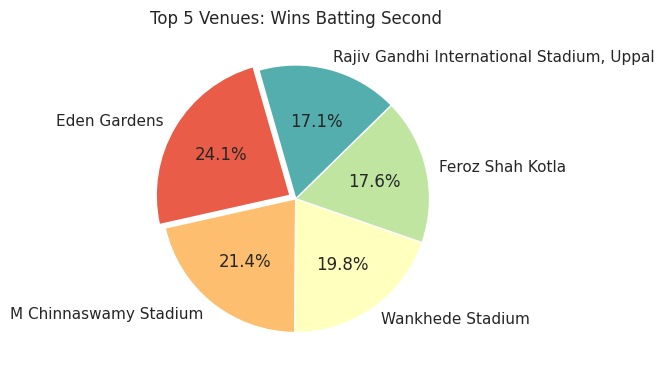

In [ ]:
second = (df[(df["win_by_wickets"] > 0) & df["venue"].notna()].groupby("venue").size().nlargest(5))

plt.figure(figsize=(6,6))
plt.pie(second.values,labels=second.index,autopct="%1.1f%%",explode=[0.05, 0, 0, 0, 0],startangle=106,colors=sns.color_palette("Spectral", len(second)))
plt.title("Top 5 Venues: Wins Batting Second")
plt.tight_layout()
plt.show()

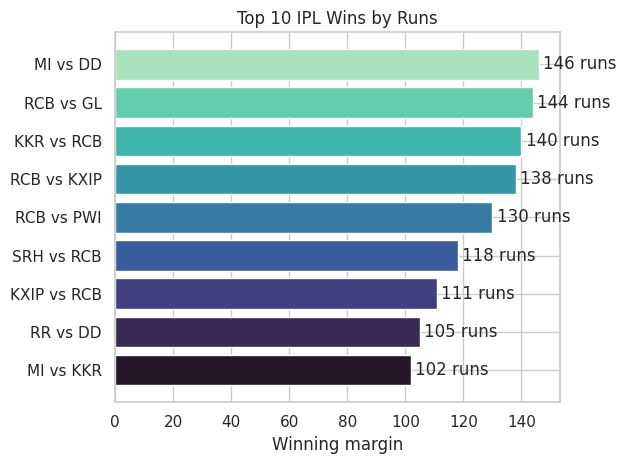

In [ ]:
m = df[df.win_by_runs > 0].copy()
m["opponent"] = np.where(m.winner == m.team1, m.team2, m.team1)
m["label"] = m.winner + " vs " + m.opponent
t = m.nlargest(9, "win_by_runs").sort_values("win_by_runs")

bars = plt.barh(t.label, t.win_by_runs, color=sns.color_palette("mako", len(t)))
plt.bar_label(bars, fmt="%.0f runs", padding=3)
plt.title("Top 10 IPL Wins by Runs")
plt.xlabel("Winning margin")
plt.tight_layout()
plt.show()

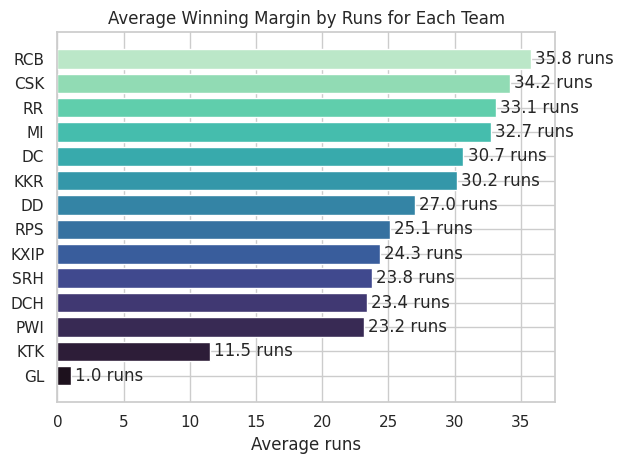

In [ ]:
avg_runs = {}
for team in df.winner.dropna().unique():
    runs = df.loc[(df.winner == team) & (df.win_by_runs > 0), "win_by_runs"]
    if not runs.empty:
        avg_runs[team] = runs.mean()
avg = pd.Series(avg_runs).sort_values()
bars = plt.barh(avg.index, avg.values, color=sns.color_palette("mako", len(avg)))
plt.bar_label(bars, fmt="%.1f runs", padding=3)
plt.title("Average Winning Margin by Runs for Each Team")
plt.xlabel("Average runs")
plt.tight_layout()
plt.show()